# Cellpose Parameter Sweep with Manual Mask Comparison

This notebook runs Cellpose over a grid of parameters, computes segmentation-quality metrics, and optionally compares each Cellpose segmentation against a manually drawn mask file using IoU matching.

It saves:
- individual mask files for each parameter combination
- a summary CSV
- ranked tables showing which parameter sets best match your manual ROIs

## 1. Imports

In [25]:
import numpy as np
import pandas as pd
from pathlib import Path
from itertools import product
import matplotlib.pyplot as plt
import tifffile

from cellpose import models
from skimage.measure import regionprops, perimeter
from scipy.optimize import linear_sum_assignment

## 2. Set paths

Change these paths to match your data. The manual mask file can be either:
- a plain labeled mask array, where 0 = background and 1, 2, 3... = ROIs
- a Cellpose `*_seg.npy` dictionary containing a `masks` field

In [26]:
# ----- INPUTS -----

# Image used for Cellpose segmentation.
# This can be a Suite2p mean image or another 2D image saved as .npy.
img_path = Path('/Users/megyoung/Desktop/mini2p Images/detrended/suite2p/plane0/meanImg_ch1.tiff')

# Optional manual mask file.
# Put None if you do not want to compare against manual masks.
# Example: manual_mask_path = Path('meanImg_ch1_manual_seg.npy')
manual_mask_path = Path('/Users/megyoung/Desktop/mini2p Images/detrended/suite2p/plane0/meanImg_ch1_seg.npy')

# Set to False if you do not have a manual mask yet.
use_manual_comparison = True

# Output folder
out_dir = Path('/Users/megyoung/Desktop/mini2p Images/detrended/cellpose_param_sweep')
out_dir.mkdir(exist_ok=True)

if img_path.suffix.lower() in [".tif", ".tiff"]:
    img = tifffile.imread(img_path)
else:
    img = np.load(img_path, allow_pickle=True)

if img.ndim == 3:
    print("Image has 3 dimensions:", img.shape)

    if img.shape[-1] in [3, 4]:
        img = img[..., 0]   # converts (512,512,4) to (512,512)
    else:
        img = img.mean(axis=0)


# If the image is accidentally saved as a dictionary, try to pull out the image.
if img.shape == () and isinstance(img.item(), dict):
    img_dict = img.item()
    if 'img' in img_dict:
        img = img_dict['img']
    elif 'meanImg' in img_dict:
        img = img_dict['meanImg']
    else:
        raise ValueError(f'Could not find image field in dictionary. Keys: {img_dict.keys()}')

print('Image shape:', img.shape)
print('Image range:', np.nanmin(img), np.nanmax(img))

Image has 3 dimensions: (512, 512, 4)
Image shape: (512, 512)
Image range: 0 255


## 3. Helper functions

In [27]:
def load_mask_npy(path):
    """
    Load either a plain labeled mask .npy file or a Cellpose *_seg.npy file.
    Returns a 2D labeled mask where 0 = background and 1..N = ROIs.
    """
    obj = np.load(path, allow_pickle=True)

    # Cellpose-style *_seg.npy is usually a 0-d object array containing a dict
    if obj.shape == () and isinstance(obj.item(), dict):
        d = obj.item()
        if 'masks' not in d:
            raise ValueError(f'File is a dictionary but has no masks key. Keys: {d.keys()}')
        return d['masks']

    # Some saved objects may already be dictionaries
    if isinstance(obj, dict):
        if 'masks' not in obj:
            raise ValueError(f'Dictionary has no masks key. Keys: {obj.keys()}')
        return obj['masks']

    # Otherwise assume it is already a labeled mask image
    return obj


def segmentation_shape_metrics(masks):
    """
    Compute basic mask metrics for one labeled mask image.
    """
    n_rois = int(masks.max())

    if n_rois == 0:
        return {
            'n_rois': 0,
            'mean_area_px': np.nan,
            'median_area_px': np.nan,
            'mean_circularity': np.nan,
            'fraction_image_covered': 0,
        }

    props = regionprops(masks.astype(int))
    areas = np.array([p.area for p in props])
    perims = np.array([perimeter(masks == p.label) for p in props])
    circularity = 4 * np.pi * areas / (perims**2 + 1e-9)

    return {
        'n_rois': n_rois,
        'mean_area_px': areas.mean(),
        'median_area_px': np.median(areas),
        'mean_circularity': np.nanmean(circularity),
        'fraction_image_covered': np.mean(masks > 0),
    }


def compare_masks_iou(pred_masks, manual_masks, iou_threshold=0.5):
    """
    Compare predicted masks to manual masks using IoU and Hungarian matching.

    Each manual ROI can match at most one predicted ROI, and each predicted ROI
    can match at most one manual ROI.
    """
    if pred_masks.shape != manual_masks.shape:
        raise ValueError(
            f'Predicted mask shape {pred_masks.shape} does not match manual mask shape {manual_masks.shape}'
        )

    pred_ids = np.array([i for i in np.unique(pred_masks) if i != 0])
    manual_ids = np.array([i for i in np.unique(manual_masks) if i != 0])

    if len(pred_ids) == 0 or len(manual_ids) == 0:
        return {
            'manual_n': len(manual_ids),
            'pred_n': len(pred_ids),
            'matched_to_manual': 0,
            'precision': 0,
            'recall': 0,
            'f1': 0,
            'mean_iou_matched': np.nan,
            'median_iou_matched': np.nan,
        }

    iou_matrix = np.zeros((len(manual_ids), len(pred_ids)), dtype=float)

    # Precompute binary masks to avoid repeated equality checks for large images
    manual_binary = [(manual_masks == mid) for mid in manual_ids]
    pred_binary = [(pred_masks == pid) for pid in pred_ids]

    for i, manual_roi in enumerate(manual_binary):
        for j, pred_roi in enumerate(pred_binary):
            intersection = np.logical_and(manual_roi, pred_roi).sum()
            union = np.logical_or(manual_roi, pred_roi).sum()
            if union > 0:
                iou_matrix[i, j] = intersection / union

    # Hungarian matching maximizes total IoU by minimizing negative IoU
    row_ind, col_ind = linear_sum_assignment(-iou_matrix)
    matched_ious = iou_matrix[row_ind, col_ind]
    good_matches = matched_ious >= iou_threshold

    n_matched = int(good_matches.sum())
    precision = n_matched / len(pred_ids) if len(pred_ids) else 0
    recall = n_matched / len(manual_ids) if len(manual_ids) else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    good_ious = matched_ious[good_matches]

    return {
        'manual_n': len(manual_ids),
        'pred_n': len(pred_ids),
        'matched_to_manual': n_matched,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'mean_iou_matched': np.mean(good_ious) if n_matched > 0 else np.nan,
        'median_iou_matched': np.median(good_ious) if n_matched > 0 else np.nan,
    }


def safe_name(diameter, cellprob, flow):
    return (
        f'diam{diameter}_cellprob{cellprob}_flow{flow}'
        .replace('.', 'p')
        .replace('-', 'neg')
    )

## 4. Load manual masks, if available

In [28]:
manual_masks = None

if use_manual_comparison:
    manual_masks = load_mask_npy(manual_mask_path)
    print('Manual mask shape:', manual_masks.shape)
    print('Number of manual ROIs:', int(manual_masks.max()))

    if manual_masks.shape != img.shape:
        raise ValueError(
            f'Manual mask shape {manual_masks.shape} does not match image shape {img.shape}. '
            'Make sure the manual masks were drawn on the same image used for Cellpose.'
        )
else:
    print('Manual comparison disabled.')

Manual mask shape: (512, 512)
Number of manual ROIs: 139


## 5. Choose Cellpose parameter grid

Adjust these values depending on your image scale. For Mini2P soma segmentation, useful sweeps often include several small diameters and a broad range of cell probability thresholds.

In [29]:
diameters = [6, 8, 10, 12, 14]
cellprob_thresholds = [-6, -4, -2, 0, 1]
flow_thresholds = [0.4, 0.6, 0.8, 1, 1.2, 1.4, 1.6, 1.8, 2]

# IoU threshold for calling a Cellpose ROI a match to a manual ROI
iou_threshold = 0.5

# Cellpose model. Change model_type if needed: 'cyto3', 'cyto2', 'nuclei', etc.
model = models.CellposeModel(gpu=True)

## 6. Run parameter sweep

In [30]:
results = []

for diameter, cellprob, flow in product(diameters, cellprob_thresholds, flow_thresholds):
    print(f'Running diameter={diameter}, cellprob={cellprob}, flow={flow}')

    masks, flows, styles = model.eval(
        img,
        channels=[0, 0],
        diameter=diameter,
        cellprob_threshold=cellprob,
        flow_threshold=flow,
        normalize=True,
    )

    name = safe_name(diameter, cellprob, flow)
    mask_file = out_dir / f'{name}_masks.npy'
    np.save(mask_file, masks)

    shape_metrics = segmentation_shape_metrics(masks)

    row = {
        'diameter': diameter,
        'cellprob_threshold': cellprob,
        'flow_threshold': flow,
        **shape_metrics,
        'mask_file': str(mask_file),
    }

    if use_manual_comparison:
        comparison = compare_masks_iou(
            pred_masks=masks,
            manual_masks=manual_masks,
            iou_threshold=iou_threshold,
        )
        row.update(comparison)

    results.append(row)

df = pd.DataFrame(results)
df.to_csv(out_dir / 'cellpose_parameter_sweep_summary.csv', index=False)
df

channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used


Running diameter=6, cellprob=-6, flow=0.4


channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used


Running diameter=6, cellprob=-6, flow=0.6


channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used


...

channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used


Running diameter=14, cellprob=1, flow=1.8


channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used


Running diameter=14, cellprob=1, flow=2


,diameter,cellprob_threshold,flow_threshold,n_rois,mean_area_px,median_area_px,mean_circularity,fraction_image_covered,mask_file,manual_n,pred_n,matched_to_manual,precision,recall,f1,mean_iou_matched,median_iou_matched
0,6,-6,0.4,0,NaN,NaN,NaN,0.000000,/Users/megyoung/Desktop/mini2p Images/detrende...,139,0,0,0.000000,0.000000,0.000000,NaN,NaN
1,6,-6,0.6,9,390.666667,370.0,0.928524,0.013412,/Users/megyoung/Desktop/mini2p Images/detrende...,139,9,2,0.222222,0.014388,0.027027,0.642546,0.642546
2,6,-6,0.8,20,302.150000,299.0,0.911957,0.023052,/Users/megyoung/Desktop/mini2p Images/detrende...,139,20,3,0.150000,0.021583,0.037736,0.654170,0.658065
3,6,-6,1.0,26,259.615385,260.0,0.883071,0.025749,/Users/megyoung/Desktop/mini2p Images/detrende...,139,26,5,0.192308,0.035971,0.060606,0.645519,0.658065
4,6,-6,1.2,26,259.615385,260.0,0.883071,0.025749,/Users/megyoung/Desktop/mini2p Images/detrende...,139,26,5,0.192308,0.035971,0.060606,0.645519,0.658065
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
220,14,1,1.2,2,65.500000,65.5,1.053026,0.000500,/Users/megyoung/Desktop/mini2p Images/detrende...,139,2,0,0.000000,0.000000,0.000000,NaN,NaN
221,14,1,1.4,2,65.500000,65.5,1.053026,0.000500,/Users/megyoung/Desktop/mini2p Images/detrende...,139,2,0,0.000000,0.000000,0.000000,NaN,NaN
222,14,1,1.6,2,65.500000,65.5,1.053026,0.000500,/Users/megyoung/Desktop/mini2p Images/detrende...,139,2,0,0.000000,0.000000,0.000000,NaN,NaN
223,14,1,1.8,2,65.500000,65.5,1.053026,0.000500,/Users/megyoung/Desktop/mini2p Images/detrende...,139,2,0,0.000000,0.000000,0.000000,NaN,NaN


## 7. Rank parameter sets

If manual masks are provided, the most useful ranking is usually by F1 score first, then mean IoU. If not, use shape metrics and visual inspection.

In [31]:
if use_manual_comparison:
    ranked = df.sort_values(
        ['f1', 'mean_iou_matched', 'recall', 'precision'],
        ascending=[False, False, False, False],
    )
else:
    ranked = df.sort_values(
        ['n_rois', 'mean_circularity'],
        ascending=[False, False],
    )

ranked.head(15)

,diameter,cellprob_threshold,flow_threshold,n_rois,mean_area_px,median_area_px,mean_circularity,fraction_image_covered,mask_file,manual_n,pred_n,matched_to_manual,precision,recall,f1,mean_iou_matched,median_iou_matched
111,10,-2,1.0,57,268.701754,241.0,0.849629,0.058426,/Users/megyoung/Desktop/mini2p Images/detrende...,139,57,16,0.280702,0.115108,0.163265,0.569806,0.547879
112,10,-2,1.2,57,268.701754,241.0,0.849629,0.058426,/Users/megyoung/Desktop/mini2p Images/detrende...,139,57,16,0.280702,0.115108,0.163265,0.569806,0.547879
113,10,-2,1.4,57,268.701754,241.0,0.849629,0.058426,/Users/megyoung/Desktop/mini2p Images/detrende...,139,57,16,0.280702,0.115108,0.163265,0.569806,0.547879
114,10,-2,1.6,57,268.701754,241.0,0.849629,0.058426,/Users/megyoung/Desktop/mini2p Images/detrende...,139,57,16,0.280702,0.115108,0.163265,0.569806,0.547879
115,10,-2,1.8,57,268.701754,241.0,0.849629,0.058426,/Users/megyoung/Desktop/mini2p Images/detrende...,139,57,16,0.280702,0.115108,0.163265,0.569806,0.547879
116,10,-2,2.0,57,268.701754,241.0,0.849629,0.058426,/Users/megyoung/Desktop/mini2p Images/detrende...,139,57,16,0.280702,0.115108,0.163265,0.569806,0.547879
93,10,-6,1.0,58,278.965517,254.5,0.841195,0.061722,/Users/megyoung/Desktop/mini2p Images/detrende...,139,58,14,0.241379,0.100719,0.142132,0.561436,0.529100
94,10,-6,1.2,58,278.965517,254.5,0.841195,0.061722,/Users/megyoung/Desktop/mini2p Images/detrende...,139,58,14,0.241379,0.100719,0.142132,0.561436,0.529100
95,10,-6,1.4,58,278.965517,254.5,0.841195,0.061722,/Users/megyoung/Desktop/mini2p Images/detrende...,139,58,14,0.241379,0.100719,0.142132,0.561436,0.529100
96,10,-6,1.6,58,278.965517,254.5,0.841195,0.061722,/Users/megyoung/Desktop/mini2p Images/detrende...,139,58,14,0.241379,0.100719,0.142132,0.561436,0.529100


## 8. Plot segmentation metrics

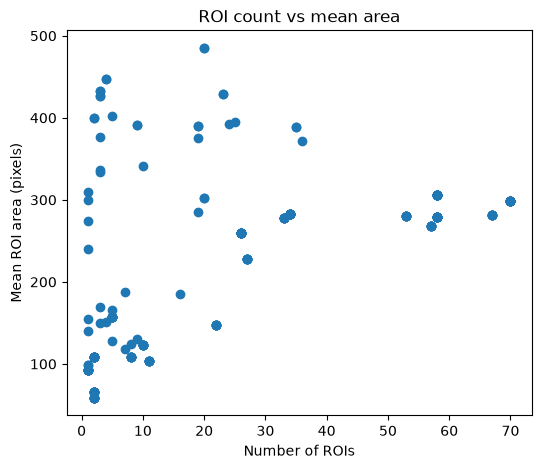

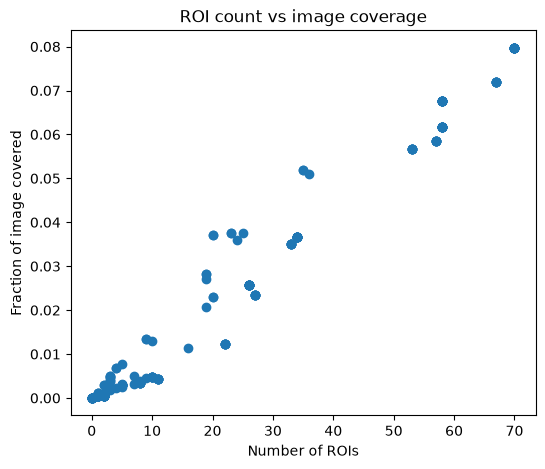

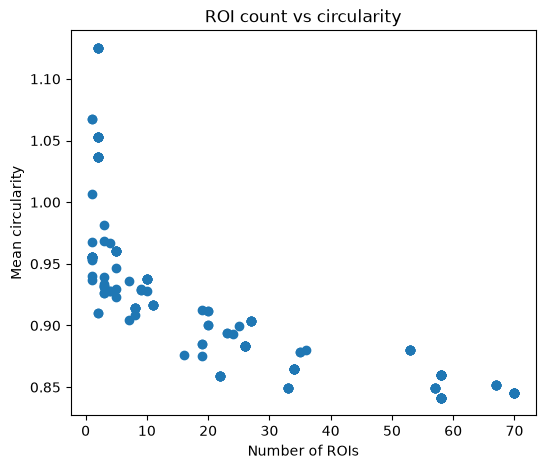

In [32]:
plt.figure(figsize=(6, 5))
plt.scatter(df['n_rois'], df['mean_area_px'])
plt.xlabel('Number of ROIs')
plt.ylabel('Mean ROI area (pixels)')
plt.title('ROI count vs mean area')
plt.show()

plt.figure(figsize=(6, 5))
plt.scatter(df['n_rois'], df['fraction_image_covered'])
plt.xlabel('Number of ROIs')
plt.ylabel('Fraction of image covered')
plt.title('ROI count vs image coverage')
plt.show()

plt.figure(figsize=(6, 5))
plt.scatter(df['n_rois'], df['mean_circularity'])
plt.xlabel('Number of ROIs')
plt.ylabel('Mean circularity')
plt.title('ROI count vs circularity')
plt.show()

## 9. Plot manual-comparison metrics

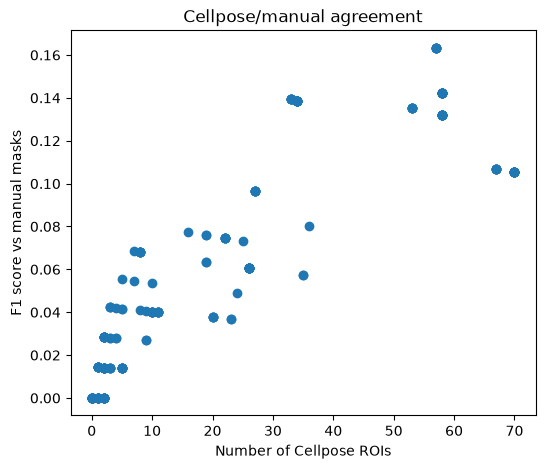

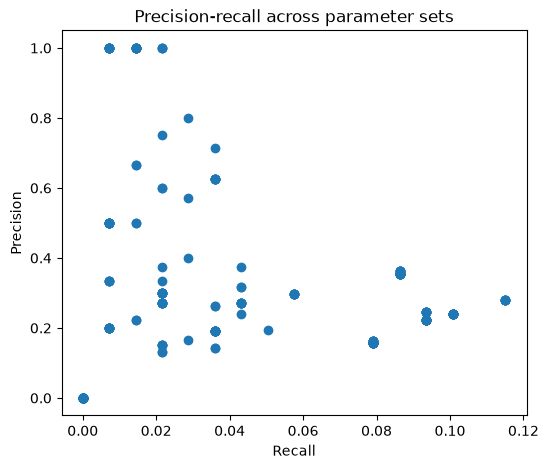

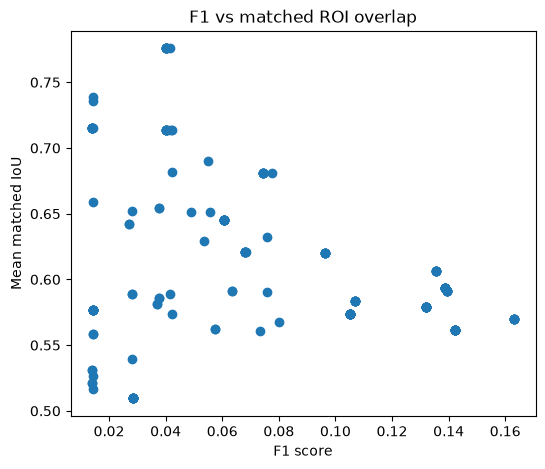

In [33]:
if use_manual_comparison:
    plt.figure(figsize=(6, 5))
    plt.scatter(df['n_rois'], df['f1'])
    plt.xlabel('Number of Cellpose ROIs')
    plt.ylabel('F1 score vs manual masks')
    plt.title('Cellpose/manual agreement')
    plt.show()

    plt.figure(figsize=(6, 5))
    plt.scatter(df['recall'], df['precision'])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-recall across parameter sets')
    plt.show()

    plt.figure(figsize=(6, 5))
    plt.scatter(df['f1'], df['mean_iou_matched'])
    plt.xlabel('F1 score')
    plt.ylabel('Mean matched IoU')
    plt.title('F1 vs matched ROI overlap')
    plt.show()
else:
    print('Manual comparison disabled.')

## 10. Visualize best masks

This shows the top-ranked masks over the original image. You can change `n_show`.

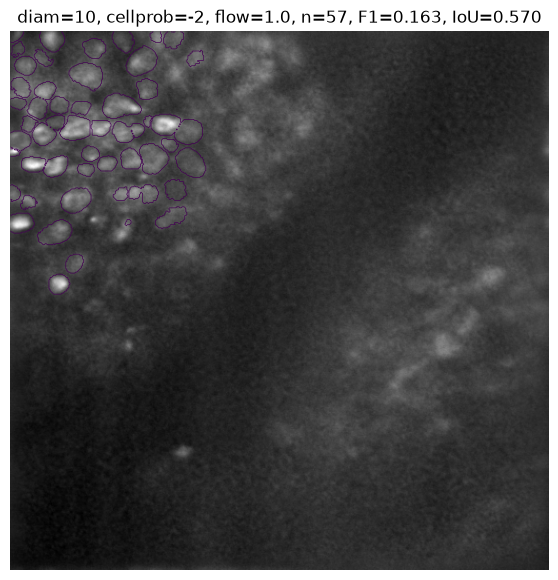

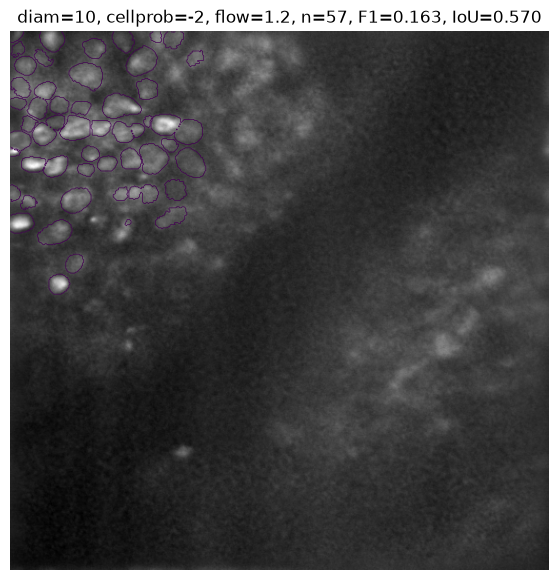

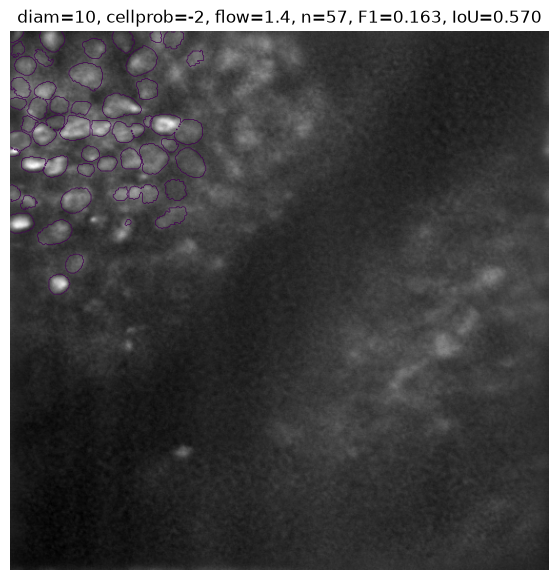

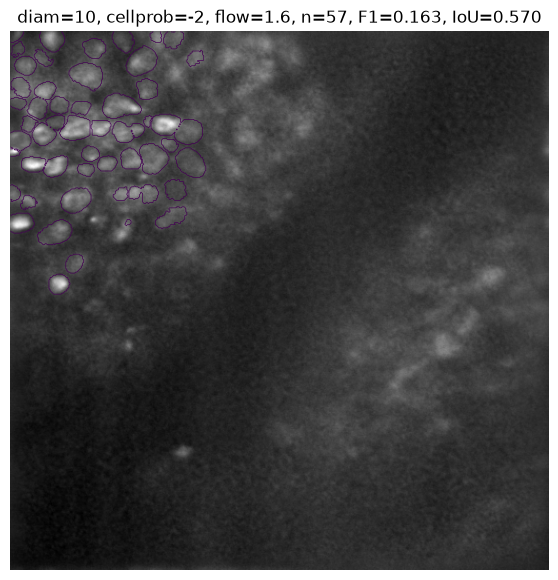

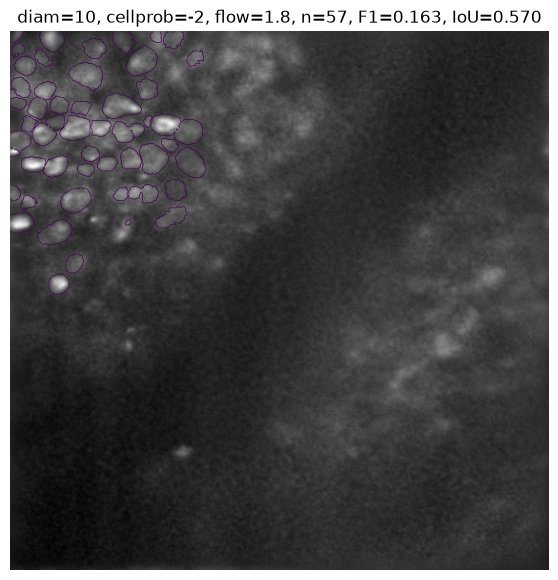

In [34]:
n_show = 5

for idx, row in ranked.head(n_show).iterrows():
    masks = np.load(row['mask_file'], allow_pickle=True)

    plt.figure(figsize=(7, 7))
    plt.imshow(img, cmap='gray')
    plt.contour(masks > 0, levels=[0.5], linewidths=0.5)

    title = (
        f"diam={row['diameter']}, cellprob={row['cellprob_threshold']}, "
        f"flow={row['flow_threshold']}, n={row['n_rois']}"
    )
    if use_manual_comparison:
        title += f", F1={row['f1']:.3f}, IoU={row['mean_iou_matched']:.3f}"

    plt.title(title)
    plt.axis('off')
    plt.show()

## 11. Save the best mask separately

In [35]:
best = ranked.iloc[0]
best_masks = np.load(best['mask_file'], allow_pickle=True)

best_mask_path = out_dir / 'best_cellpose_masks.npy'
np.save(best_mask_path, best_masks)

print('Best parameter set:')
print(best)
print('\nSaved best mask to:', best_mask_path)

Best parameter set:
diameter                                                                 10
cellprob_threshold                                                       -2
flow_threshold                                                          1.0
n_rois                                                                   57
mean_area_px                                                     268.701754
median_area_px                                                        241.0
mean_circularity                                                   0.849629
fraction_image_covered                                             0.058426
mask_file                 /Users/megyoung/Desktop/mini2p Images/detrende...
manual_n                                                                139
pred_n                                                                   57
matched_to_manual                                                        16
precision                                                          0